# Nearest neighbour searches

*Python port of the R vignette [Nearest neighbour searches in manifoldsR](https://gregorlueg.github.io/manifoldsR/articles/knn_searches.html). Original author: Gregor Lueg.*

kNN graphs sit underneath nearly every method in this package. UMAP, densMAP,
t-SNE, PaCMAP, LocalMAP, PHATE, diffusion maps and ForceAtlas2 all start from
one. This vignette walks through the backends, what each is good at, how
exact the approximate ones are, and how to build a graph once and hand it to
several estimators instead of recomputing it every time.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from pynndescent import NNDescent
from sklearn.neighbors import NearestNeighbors

import manifolds_rs as mf

K = 10

## Exhaustive search

The simplest one. A flat index with SIMD distance kernels, so it is cache
friendly and on small data it beats the approximate searches, which have to
build an index first. `knn_graph` hands back indices and distances as two
`(n_samples, k)` arrays, self excluded.

In [2]:
X, labels = mf.datasets.clustered(1_000)

indices, distances = mf.knn_graph(X, k=K, ann="exhaustive")

print(indices.shape, indices.dtype, distances.dtype)
indices[:3]

(1000, 10) int64 float64


array([[625, 320, 442, 817,  59, 447, 491, 235, 206, 205],
       [ 75, 759, 926, 825, 335, 993, 569, 557, 535, 892],
       [932, 983, 915, 743, 253, 163, 329, 873,  20, 479]])

Indices first, distances second. That is the opposite of scikit-learn's
`kneighbors`, and it is the order every estimator takes them in.

An exact alternative is
[kMkNN](https://ieeexplore.ieee.org/document/6033373) (k-means for k-nearest
neighbours). It clusters the data with k-means and uses the triangle
inequality to skip most of the distance computations. Very fast on data with
strong structure and modest dimensionality, and the default of `knn_graph`.

In [3]:
indices_kmknn, _ = mf.knn_graph(X, k=K, ann="kmknn")

np.array_equal(indices, indices_kmknn)

True

## Approximate searches

The package is built for large data and pulls its approximate searches from
[ann-search-rs](https://github.com/GregorLueg/ann-search-rs). Five of them
are exposed, on top of the two exact ones:

| Method | Class | Use case |
| --- | --- | --- |
| `"balltree"` | Tree | Small data, low dimensionality. |
| `"annoy"` | Tree | A single-cell classic. Scales to a few hundred thousand points at low dimensionality. |
| `"hnsw"` | Graph | Large data (500k and up), any dimensionality. Slower build, fast queries. The build uses a benign race. |
| `"nndescent"` | Graph | The all-rounder from 100k points on. Default for UMAP, densMAP and ForceAtlas2. |
| `"ivf"` | Cluster | The index behind FAISS. Large data, any dimensionality. `n_probes` trades recall for speed. Default for the t-SNE family, PaCMAP, LocalMAP and PHATE. |

Every backend bar `"exhaustive"` searches in float32, whatever you hand it,
and casts the distances back to your dtype. Same recall, less memory traffic.
The knobs per backend live in `NeighbourParams`; only the fields of the
backend you picked do anything.

In [4]:
mf.NeighbourParams()

NeighbourParams(n_tree=None, search_budget=None, m=None, ef_construction=None, ef_search=None, delta=None, bt_budget=None, n_list=None, n_probes=None)

### Speed

Every backend at three sizes, one run each. scikit-learn's exact search and
[pynndescent](https://github.com/lmcinnes/pynndescent) (what umap-learn uses)
are in there for reference. pynndescent compiles with numba on first use, so
it gets one warm-up call before the clock starts.

In [5]:
BACKENDS = ["exhaustive", "kmknn", "balltree", "annoy", "hnsw", "nndescent", "ivf"]

NNDescent(X, n_neighbors=K + 1, random_state=42).neighbor_graph


def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start


def time_backends(X: np.ndarray) -> dict[str, float]:
    """Wall time of every manifolds-rs backend and the two references on `X`."""
    params = mf.NeighbourParams(n_probes=25)
    res = {
        ann: timed(lambda ann=ann: mf.knn_graph(X, k=K, ann=ann, nn_params=params))
        for ann in BACKENDS
    }
    res["sklearn (exact)"] = timed(
        lambda: NearestNeighbors(n_neighbors=K).fit(X).kneighbors()
    )
    res["pynndescent"] = timed(
        lambda: NNDescent(X, n_neighbors=K + 1, random_state=42).neighbor_graph
    )
    return res


speed = {
    f"{n // 1000}k": time_backends(mf.datasets.clustered(n)[0])
    for n in (1_000, 50_000, 100_000)
}

pl.DataFrame(
    {"method": list(speed["1k"]), **{n: list(t.values()) for n, t in speed.items()}}
).with_columns(pl.exclude("method").round(3))

method,1k,50k,100k
str,f64,f64,f64
"""exhaustive""",0.002,0.822,3.18
"""kmknn""",0.004,0.409,1.395
"""balltree""",0.002,0.321,1.262
"""annoy""",0.008,1.023,3.332
"""hnsw""",0.008,1.006,3.075
"""nndescent""",0.006,0.202,0.526
"""ivf""",0.005,0.322,0.828
"""sklearn (exact)""",0.074,1.039,4.065
"""pynndescent""",0.014,0.215,0.398


Times in seconds. On 1k points nothing matters: exhaustive is as fast as
anything, since every other backend has to build an index first and SIMD does
the `O(N^2)` in no time at that size. From 50k on NN-Descent and IVF pull
ahead, and the gap grows with N. kMkNN, which is exact, comes in at about half
the exhaustive time on this tightly clustered data.

Annoy and HNSW are no faster than exhaustive here: a one-off self-query at
`k = 10` never pays back their index build. They earn their keep at larger N,
or when you query the same index again and again. pynndescent looks faster
than our NN-Descent, but hold that thought until the recall below.

### Precision

Approximate means approximate. Two numbers against the exhaustive ground
truth on 25k points:

- Recall@k: fraction of the true `k` neighbours found, in any order.
- Mean distance ratio: distance to the found neighbour over the distance to
  the true one at the same rank. `1.0` is perfect, and it tells you how wrong
  the misses are.

In [6]:
X_25k, _ = mf.datasets.clustered(25_000)
true_idx, true_dist = mf.knn_graph(X_25k, k=K, ann="exhaustive")


def precision(ann: str) -> dict[str, float | str]:
    """Recall@k and mean distance ratio of one backend against exhaustive."""
    idx, dist = mf.knn_graph(
        X_25k, k=K, ann=ann, nn_params=mf.NeighbourParams(n_probes=25)
    )
    hits = sum(len(set(a) & set(b)) for a, b in zip(idx, true_idx, strict=True))
    return {
        "method": ann,
        "recall": hits / true_idx.size,
        "dist_ratio": float(np.mean(dist / true_dist)),
    }


pynn, _ = NNDescent(X_25k, n_neighbors=K + 1, random_state=42).neighbor_graph
pynn_dist = np.linalg.norm(X_25k[:, None, :] - X_25k[pynn[:, 1:]], axis=2)
pynn_row = {
    "method": "pynndescent",
    "recall": sum(
        len(set(a) & set(b)) for a, b in zip(pynn[:, 1:], true_idx, strict=True)
    )
    / true_idx.size,
    "dist_ratio": float(np.mean(pynn_dist / true_dist)),
}

pl.DataFrame([precision(ann) for ann in BACKENDS[1:]] + [pynn_row]).with_columns(
    pl.col("recall", "dist_ratio").round(4)
)

method,recall,dist_ratio
str,f64,f64
"""kmknn""",1.0,1.0
"""balltree""",0.932,1.0023
"""annoy""",0.9999,1.0
"""hnsw""",0.999,1.0
"""nndescent""",0.923,1.002
"""ivf""",0.9864,1.0004
"""pynndescent""",0.7764,1.0078


Look at the distance ratio before you panic about a recall number. The
synthetic clusters are tight, so lots of points sit at nearly identical
distances and swapping one for another costs nothing. For manifold learning
that is exactly the kind of miss you don't care about.

pynndescent's speed comes at a price in recall. Part of it is the seeding
forest: by default it plants `2 * log10(n)` trees (at most 12), ours
`5 + sqrt(n) / 20` (at most 64), so about twice as many at 100k. Give
pynndescent the same number of trees and it is still a bit faster, with
clearly lower recall on this data. For a much deeper
comparison of the methods, see the
[ann-search-rs benchmarks](https://github.com/GregorLueg/ann-search-rs).

## Build once, embed many times

On anything large the neighbour search is most of the runtime. Running UMAP
with three different `min_dist` values, plus t-SNE, plus PaCMAP? Build the
graph once and pass it in. Each estimator takes `knn_indices` and
`knn_distances` in `fit` / `fit_transform`.

Mind the width. UMAP takes `n_neighbors` neighbours and cuts a wider graph
down (with a warning on stderr). t-SNE wants `3 * perplexity`. PaCMAP and
LocalMAP want `n_near + 50`, because the near pairs are the best `n_near` of a
wider search by locally scaled distance. So build the widest one you need.

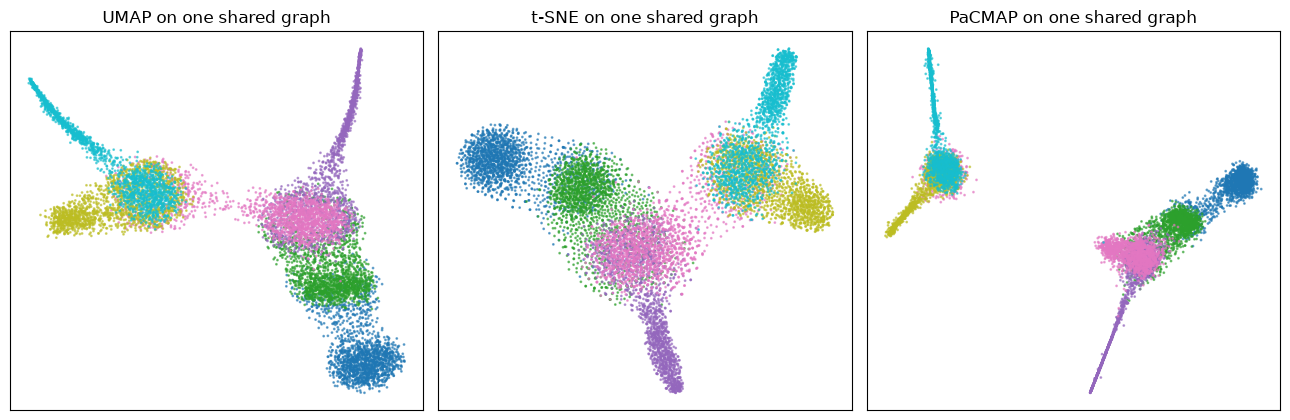

In [7]:
X_traj, labels_traj = mf.datasets.trajectory(10_000)

idx, dist = mf.knn_graph(X_traj, k=90, ann="nndescent")

embeddings = {
    "UMAP": mf.UMAP().fit_transform(
        X_traj, knn_indices=idx[:, :15], knn_distances=dist[:, :15]
    ),
    "t-SNE": mf.TSNE(perplexity=30.0).fit_transform(
        X_traj, knn_indices=idx, knn_distances=dist
    ),
    "PaCMAP": mf.PaCMAP().fit_transform(
        X_traj, knn_indices=idx[:, :60], knn_distances=dist[:, :60]
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, emb) in zip(axes, embeddings.items(), strict=True):
    ax.scatter(emb[:, 0], emb[:, 1], c=labels_traj, s=1, cmap="tab10", alpha=0.6)
    ax.set_title(f"{name} on one shared graph")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

One search, three embeddings. The graph is just two numpy arrays, so you can
also build it on the GPU and run the embedding on the CPU, or the other way
round. The [GPU vignette](../gpu/) has that.